## **E X P E R I M E N T S**

Una vez tenga los hiperparámteros de EGPA obtenido con el approach global para todos los problemas a la vez ejecuto los experimentos

**Consideraciones:**
1. Estimación de hiperparámteros de EGPA con Bayesian Optimization (BO)
    - Enfoque global considerando los tres problemas a la vez mejorando MSE del peor 3BO (1 por cada número de variables) **DONE**
    - Enfoque específico de cada problema y su número de variables (9BO) **Not DONE**
    - Parámetros al azar para confirmar robustez o no **Not DONE**
2. Tres problemas [Pozo infinito, Oscilador armónico, NLSE] para
3. Tres números de variables [50, 425, 800]
4. Para estos tres problemas las medidas que se toman son:
    - Valor de la energía con error relativo (%)
    - MSE respecto de soluciones analíticas
    - Predicción de GP aprendido a 1000 puntos (MSE cometido en esos puntos vs solución analítica con 1000 puntos) 
    - Tiempo de ejecución para hallar dicho nivel

In [1]:
from EGPA import *
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.oneDQHarmOscillatorfunctions import *
from OptFunctions.NonLinearSE import *
from OptFunctions.oneDwellfunctions import *
#from utils import _parallel_apply_along_axis
import time
import warnings
warnings.filterwarnings("ignore")
import pickle

In [2]:
#Medidas de los experimentos se guardan en un array.shape [Nexp, 9, 5]
#porque se harán Nexp ejecuciones de los problemas
# 9 filas porque tenemos 4 estados de Oscilador, 4 de pozo y 1 de NLSE
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
# en este orden de manera que por ejemplo los E% de los Nexp del estado Psi0 del pozo es el elemento [:, 4, 2] del array de Resultados

n_variables = [50, 425, 800] #Tamaños del grid (número de dimensiones del problema de optimización)
for vars in n_variables:

    #In the case of EGPA algorithm the parameters are optimized in a general way and not problem by problem.
    ruta = f'BO_params/{vars}EGPA'
    with open(f'{ruta}.pkl', "rb") as file:
        BO_params = pickle.load(file)

    # for keys in BO_params.keys():
    #     print(BO_params[keys])
    
    size_gen = BO_params['params']['size_gen']
    alpha = BO_params['params']['alpha']
    elite_factor = BO_params['params']['elite_factor']
    dead_iter = BO_params['params']['dead_iter'] #dead iter was optimized but it is not used. It is just a stop criteria for the algorithm which will be fixed.
    init_kernels = BO_params['params']['init_kernels']
    std_lower_bound = BO_params['params']['std_lower_bound']

    #### STOP CRITERIA ##### based on max number of function evaluations fixed at 1 x 10^6
    max_f_evals = 1*10**6 # max_f_evals = max_iter * size_gen.  
    max_iter = int(max_f_evals/size_gen)
    dead_iter = int(max_iter*0.05) #dead_iter = 5% of max_iter
    #older criteria max_iter = 600 ##No se optimiza pero se fija para todos los exps.

    Nexp = 10
    Resultados = np.empty((Nexp, 9, 5)) 
    print(f'\n\n########################### Experimentos con {vars} variables ###########################\n\n')
    for experimento in range(Nexp):
        print(f'\n\n########################### Ejecución de Experimentos número: {experimento+1} de {Nexp} ###########################\n\n')

        ##########################################################################################
        ##########################################################################################
        ########################### OSCILADOR ARMÓNICO ###########################################
        ##########################################################################################
        print('Quantum Harmonic Oscillator IN PROGRESS\n')
        #Problem grid definition
        X_grid = np.linspace(start=-4, stop=4, num=vars).reshape(-1,1) #para que sean n_variables filas y 1 columna
        #Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
        #Los datos que conocemos son las amplitudes en x=-4 (-inf) x=4 (inf) que son 0
        X_train = X_grid[[0,-1]]
        Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
        #Grid de 1000 puntos
        GPX_grid = np.linspace(start=-4, stop=4, num=1000).reshape(-1,1)

        #Analytical solutions definitions
        #Ground state
        APsi0 = np.exp(-X_grid**2/2)
        integral =0
        for i in range(len(APsi0)):
            integral = integral + (APsi0[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi0)-1))

        B = (1/integral)**0.5
        APsi0 = B * APsi0

        #1st excitated state
        APsi1 = np.exp(-X_grid**2/2)*2*X_grid
        integral =0
        for i in range(len(APsi1)):
            integral = integral + (APsi1[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi1)-1))

        B = (1/integral)**0.5
        APsi1 = -1 * B * APsi1 #signo menos para correspondencia con solución algoritmo (simetrización)

        #2nd excitated state
        APsi2 = np.exp(-X_grid**2/2)*(4*X_grid**2-2)
        integral =0
        for i in range(len(APsi2)):
            integral = integral + (APsi2[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi2)-1))

        B = (1/integral)**0.5
        APsi2 = B * APsi2

        #3rd excitated state
        APsi3 = np.exp(-X_grid**2/2)*(8*X_grid**3-12*X_grid)
        integral =0
        for i in range(len(APsi3)):
            integral = integral + (APsi3[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi3)-1))

        B = (1/integral)**0.5
        APsi3 = -1 * B * APsi3 #signo menos para correspondencia con solución algoritmo (simetrización)

        APsis = {}
        APsis['APsi0'] = APsi0[:, 0]
        APsis['APsi1'] = APsi1[:, 0]
        APsis['APsi2'] = APsi2[:, 0]
        APsis['APsi3'] = APsi3[:, 0]

        ## 1000 puntos analytical solutions
        #Analytical solutions definitions
        #Ground state
        GPAPsi0 = np.exp(-GPX_grid**2/2)
        integral =0
        for i in range(len(GPAPsi0)):
            integral = integral + (GPAPsi0[i]**2)*((GPX_grid[-1]-GPX_grid[0])/(len(GPAPsi0)-1))

        B = (1/integral)**0.5
        GPAPsi0 = B * GPAPsi0

        #1st excitated state
        GPAPsi1 = np.exp(-GPX_grid**2/2)*2*GPX_grid
        integral =0
        for i in range(len(GPAPsi1)):
            integral = integral + (GPAPsi1[i]**2)*((GPX_grid[-1]-GPX_grid[0])/(len(GPAPsi1)-1))

        B = (1/integral)**0.5
        GPAPsi1 = -1 * B * GPAPsi1 #signo menos para correspondencia con solución algoritmo (simetrización)

        #2nd excitated state
        GPAPsi2 = np.exp(-GPX_grid**2/2)*(4*GPX_grid**2-2)
        integral =0
        for i in range(len(GPAPsi2)):
            integral = integral + (GPAPsi2[i]**2)*((GPX_grid[-1]-GPX_grid[0])/(len(GPAPsi2)-1))

        B = (1/integral)**0.5
        GPAPsi2 = B * GPAPsi2

        #3rd excitated state
        GPAPsi3 = np.exp(-GPX_grid**2/2)*(8*GPX_grid**3-12*GPX_grid)
        integral =0
        for i in range(len(GPAPsi3)):
            integral = integral + (GPAPsi3[i]**2)*((GPX_grid[-1]-GPX_grid[0])/(len(GPAPsi3)-1))

        B = (1/integral)**0.5
        GPAPsi3 = -1 * B * GPAPsi3 #signo menos para correspondencia con solución algoritmo (simetrización)

        GPAPsis = {}
        GPAPsis['GPAPsi0'] = GPAPsi0[:, 0]
        GPAPsis['GPAPsi1'] = GPAPsi1[:, 0]
        GPAPsis['GPAPsi2'] = GPAPsi2[:, 0]
        GPAPsis['GPAPsi3'] = GPAPsi3[:, 0]


        ##########################################################################################################
        ##########################################################################################################

        ### Ahora el código con EGPA que calcula los 4 primeros estados excitados del problema oscilador armónico
        params = {'x':X_grid}
        #Ground state
        print(f'F should be approx -0.082')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels, std_lower_bound=std_lower_bound, parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultQHOground = Gaussian.minimize(oneDHOExpE, params, exp_from = 3, output_runtime=False)
        end = time.time()
        Resultados[experimento, 0, 4] = end-start
        #Se guardan resultados de algoritmo para siguiente estado excitado
        Psi_ground=egparesultQHOground.data[-1, 0, :-1]
        cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
        E0 = np.sqrt(-np.log(-egparesultQHOground.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así 
        params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground}
        Resultados[experimento, 0, 1] = E0
        Resultados[experimento, 0, 2] = abs(E0-0.5)/0.5*100
        GP1000MSEs = [] 
        GPPrediction = egparesultQHOground.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsis[f'GPAPsi{0}'])**2)
        GP1000MSEs.append(mse)
        print(f'\n  |Psi0> done\n')

        #1er estado excitado
        print(f'F should be approx -4.54e-5')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels, std_lower_bound=std_lower_bound, parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultQHO1 = Gaussian.minimize(oneDHOExpE1, params, exp_from = 5, output_runtime=False)
        end = time.time()
        Resultados[experimento, 1, 4] = end-start
        Psi1=egparesultQHO1.data[-1, 0, :-1]
        cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
        E1 = np.sqrt(-np.log(-egparesultQHO1.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
        Resultados[experimento, 1, 1] = E0 + E1
        Resultados[experimento, 1, 2] = abs(E0 + E1 -1.5)/1.5*100
        GPPrediction = egparesultQHO1.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsis[f'GPAPsi{1}'])**2)
        GP1000MSEs.append(mse) 
        params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1}
        print(f'\n  |Psi1> done\n')

        #2o estado excitado
        print(f'F should be approx -4.54e-5')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels, std_lower_bound=std_lower_bound, parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultQHO2 = Gaussian.minimize(oneDHOExpE2, params, exp_from = 5, output_runtime=False)
        end = time.time()
        Resultados[experimento, 2, 4] = end-start
        Psi2=egparesultQHO2.data[-1, 0, :-1]
        cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
        E2 = np.sqrt(-np.log(-egparesultQHO2.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
        Resultados[experimento, 2, 1] = E0 + E1 + E2
        Resultados[experimento, 2, 2] = abs(E0 + E1 + E2 -2.5)/2.5*100
        GPPrediction = egparesultQHO2.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsis[f'GPAPsi{2}'])**2)
        GP1000MSEs.append(mse)  
        params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2 }
        print(f'\n  |Psi2> done\n')

        #3er estado excitado
        print(f'F should be approx -4.54e-5')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels, std_lower_bound=std_lower_bound, parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultQHO3 = Gaussian.minimize(oneDHOExpE3, params, exp_from = 5, output_runtime=False)
        end = time.time()
        Resultados[experimento, 3, 4] = end-start
        Psi3=egparesultQHO3.data[-1, 0, :-1]
        cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
        E3 = np.sqrt(-np.log(-egparesultQHO3.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
        Resultados[experimento, 3, 1] = E0 + E1 + E2 + E3
        Resultados[experimento, 3, 2] = abs(E0 + E1 + E2 + E3 -3.5)/3.5*100
        GPPrediction = egparesultQHO3.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsis[f'GPAPsi{3}'])**2)
        GP1000MSEs.append(mse) 
        params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2, 'E3': E3, 'Psi3': Psi3 }
        print(f'\n  |Psi3> done\n')

        #Cálculos de métricas error MSE de cada estado con estado teórico
        MSEs = []
        for i in range(4):
            mse = np.mean((params[f'Psi{i}'] - APsis[f'APsi{i}'])**2)
            Resultados[experimento, i, 0] = mse
            MSEs.append(mse)
        #Añadimos predicciones de GP a Resultados
        Resultados[experimento,:4, 3] = GP1000MSEs
        
        print(f'MSE: {MSEs}\n') 
        print('\nQuantum Harmonic Oscillator DONE\n')

        ######################################################################################
        ######################################################################################
        ############## POZO DE POTENCIAL INFINITO 1D WELL ####################################
        ######################################################################################
        print('\nInfinite Well IN PROGRESS\n')
        L=5
        #Energías teóricas
        Eg = (2*np.pi)**2/(8*L**2*1)
        En=[]
        for i in range(4):
            e=(i+1)**2*Eg
            En.append(e)

        ## Problem grid definition
        X_grid = np.linspace(start=0, stop=L, num=vars).reshape(-1,1) #para que sean n_variables filas y 1 columna
        #Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
        #Los datos que conocemos son las amplitudes en x=0 x=5 que son 0
        X_train = X_grid[[0,-1]]
        Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
        params = {'L':L}
        ## grid for GPprediction
        GPX_grid = np.linspace(start=0, stop=L, num=1000).reshape(-1,1) #para que sean n_variables filas y 1 columna

        #Soluciones teóricas
        ### Soluciones analíticas
        # def Psi_n(n):
        #     return((2/L)**0.5*np.sin(n*np.pi*np.linspace(0, L, n_variables)/L))

        APsisWell = {}
        for n in range(4):
            APsisWell[f'APsi{n}'] = (2/L)**0.5*np.sin((n+1)*np.pi*np.linspace(0, L, vars)/L)

        GPAPsisWell = {}
        for n in range(4):
            GPAPsisWell[f'GPAPsi{n}'] = (2/L)**0.5*np.sin((n+1)*np.pi*np.linspace(0, L, 1000)/L)
        
        #Ground state n=1
        print(f'F should be approx -0.9618')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels ,parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultgroundWell = Gaussian.minimize(oneD_wellExpE, params, exp_from = 2, output_runtime=False)
        end = time.time()
        Resultados[experimento, 4, 4] = end-start
        Psi_fund=egparesultgroundWell.data[-1, 0, :-1]
        E_fund = np.sqrt(-np.log(-egparesultgroundWell.data[-1,0,-1])) # def exponencial de función de coste la energía se determina a partir del fitness así.
        #En este caso no hay constante multiplicando exponente exponencial
        Resultados[experimento, 4, 1] = E_fund
        Resultados[experimento, 4, 2] = abs(E_fund-En[0])/En[0]*100 
        GP1000MSEs = [] 
        GPPrediction = egparesultgroundWell.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsisWell[f'GPAPsi{0}'])**2)
        GP1000MSEs.append(mse)
        params = {'L':L, 'E': E_fund, 'Psi': Psi_fund}
        print(f'\n  |Psi0> done\n')

        #1excitated state n=2
        print(f'F should be approx -0.7042')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels,parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultWellexc1 = Gaussian.minimize(oneD_wellExpEexcitated, params, exp_from = 4, output_runtime=False)
        end = time.time()
        Resultados[experimento, 5, 4] = end-start
        Psi_1=egparesultWellexc1.data[-1, 0, :-1]
        E1 = np.sqrt(-np.log(-egparesultWellexc1.data[-1,0,-1]))
        Resultados[experimento, 5, 1] = E_fund + E1
        Resultados[experimento, 5, 2] = abs(E_fund + E1 -En[1])/En[1]*100
        GPPrediction = egparesultWellexc1.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsisWell[f'GPAPsi{1}'])**2)
        GP1000MSEs.append(mse) 
        params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}
        print(f'\n  |Psi1> done\n')

        #2nd excitated state n=3
        print(f'F should be approx -0.3775')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels,parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultWellexc2 = Gaussian.minimize(oneD_wellExpEexcitated3, params, exp_from = 5, output_runtime=False)
        end = time.time()
        Resultados[experimento, 6, 4] = end - start
        Psi_2=egparesultWellexc2.data[-1, 0, :-1]
        E2 = np.sqrt(-np.log(-egparesultWellexc2.data[-1,0,-1]))
        Resultados[experimento, 6, 1] = E_fund + E1 + E2
        Resultados[experimento, 6, 2] = abs(E_fund + E1 +E2 -En[2])/En[2]*100
        GPPrediction = egparesultWellexc2.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsisWell[f'GPAPsi{2}'])**2)
        GP1000MSEs.append(mse)  
        params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}
        print(f'\n  |Psi2> done\n')

        #3rd excitated state n=4
        print(f'F should be approx -0.1482')
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels,parallelize=True, init_data=(X_train, Y_train))
        start = time.time()
        egparesultWellexc3 = Gaussian.minimize(oneD_wellExpEexcitated4, params, exp_from = 9, output_runtime=False)
        end = time.time()
        Resultados[experimento, 7, 4] = end-start
        Psi_3 = egparesultWellexc3.data[-1, 0, :-1]
        E3 = np.sqrt(-np.log(-egparesultWellexc3.data[-1,0,-1]))
        Resultados[experimento, 7, 1] = E_fund + E1 + E2 + E3
        Resultados[experimento, 7, 2] = abs(E_fund + E1 +E2+E3 -En[3])/En[3]*100
        GPPrediction = egparesultWellexc3.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - GPAPsisWell[f'GPAPsi{3}'])**2)
        GP1000MSEs.append(mse)  
        params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2, 'E3':E3, 'Psi3': Psi_3}
        print(f'\n  |Psi3> done\n')

        #Cálculos de métricas error MSE de cada estado con estado teórico
        MSEs = []
        for i in range(4):
            mse = np.mean((params[f'Psi{i}'] - APsisWell[f'APsi{i}'])**2)
            Resultados[experimento, i+4, 0] = mse
            MSEs.append(mse)

        #Añadimos predicciones de GP a Resultados
        Resultados[experimento, 4:8, 3] = GP1000MSEs

        print(f'MSE: {MSEs}\n') 
        print('\nInfinite Well DONE\n')

        ######################################################################################
        ######################################################################################
        #################### N L S E Non linear Schroedinger Equation ########################
        ######################################################################################
        print('\nNLSE IN PROGRESS\n')
        if vars%2 ==0:
                varsNLSE=vars+1
        else:
            varsNLSE=vars
        L=2
        #El grid se define en para los tres problemas de optimización con el mismo número de variables
        X_grid = np.linspace(start=-1, stop=1, num=varsNLSE).reshape(-1,1) #para que sean n_variables filas y 1 columna
        #Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
        #Los datos que conocemos son las amplitudes en x=0 que son 1
        #X_train = X_grid[n_variables/12]
        X_train = np.array((0)).reshape(-1,1)
        Y_train = np.linspace(start=1, stop=1, num=1).reshape(-1,1) #Para que sea 2D array
        #Grid for GP prediction
        GPX_grid = np.linspace(start=-1, stop=1, num=1000).reshape(-1,1) #para que sean n_variables filas y 1 columna

        params = {'L':L}
        Gaussian = EGPA(size_gen=size_gen, grid_X=X_grid, max_iter=max_iter, dead_iter=dead_iter, alpha=alpha, elite_factor=elite_factor, init_kernels=init_kernels ,parallelize=True, init_data=(X_train, Y_train), normalize_solutions=False, symmetrize_solutions=False)
        start = time.time()
        egparesultNLSE = Gaussian.minimize(NLSE, params, exp_from = 400, output_runtime=False)
        end = time.time()
        Resultados[experimento, 8, 4] = end - start
        GPPrediction = egparesultNLSE.GP_hist.predict(GPX_grid)
        mse = np.mean((GPPrediction - 1/np.cosh(GPX_grid[:,0]))**2)
        Resultados[experimento, 8, 3] = mse
        #MSE calc
        #MSE_NLSE = sum((1/np.cosh(X_grid[:,0]) - egparesultNLSE.data[-1, 0, :-1])**2) / len(X_grid[:,0])
        #print(MSE_NLSE, 'using sum')
        MSE_NLSE = np.sum((1/np.cosh(X_grid[:,0]) - egparesultNLSE.data[-1, 0, :-1])**2) / len(X_grid[:,0])
        MSE_NLSE = np.float64(MSE_NLSE)
        Resultados[experimento, 8, 0] = MSE_NLSE
        print(f'MSE: {MSE_NLSE}\n') 
        print('\nNLSE DONE\n')
        print(f'\nEXPERIMENTO {experimento+1} of {Nexp} finished')
    ##################################################################################################

    rutafinal = f'EGPA_results/{vars}'    
    with open(f'{rutafinal}.pkl', "wb") as file:
        pickle.dump(Resultados, file)

        
        



########################### Experimentos con 50 variables ###########################




########################### Ejecución de Experimentos número: 1 de 10 ###########################


Quantum Harmonic Oscillator IN PROGRESS

F should be approx -0.082
	NFEVALS = 136000 F = [-0.08273432]
	X = [5.63955701e-09 9.42406651e-04 1.49782138e-03 2.12638302e-03
 3.21527107e-03 5.10494220e-03 8.15221714e-03 1.28155902e-02
 1.97407799e-02 2.98191007e-02 4.41938507e-02 6.41972437e-02
 9.12130208e-02 1.26475195e-01 1.70827015e-01 2.24476358e-01
 2.86788542e-01 3.56157037e-01 4.29984922e-01 5.04795883e-01
 5.76475476e-01 6.40624303e-01 6.92984137e-01 7.29884822e-01
 7.48650983e-01 7.47909355e-01 7.27750102e-01 6.89715395e-01
 6.36615949e-01 5.72202798e-01 5.00745021e-01 4.26577083e-01
 3.53680779e-01 2.85356178e-01 2.24016411e-01 1.71116707e-01
 1.27205895e-01 9.20704000e-02 6.49341062e-02 4.46748401e-02
 3.00266762e-02 1.97456324e-02 1.27266936e-02 8.06787197e-03
 5.08341937e-03 3.27185034e-0

In [ ]:
import pickle
ruta = 'ResultadosEXP/800EGPA'
with open(f'{ruta}.pkl', "wb") as file:
    pickle.dump(Resultados, file)

In [ ]:
#Medidas de los experimentos se guardan en un array.shape [Nexp, 9, 5]
#porque se harán Nexp ejecuciones de los problemas
# 9 filas porque tenemos 4 estados de Oscilador, 4 de pozo y 1 de NLSE
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
# en este orden de manera que por ejemplo los E% de los Nexp del estado Psi0 del pozo es el elemento [:, 4, 2] del array de Resultados
Resultados[6,:,0]

array([9.85855728e-06, 1.55802888e-05, 1.22856992e-05, 2.28238279e-05,
       4.18432672e-08, 2.18419391e-06, 2.22408297e-06, 2.63619760e-05,
       7.93599565e-06])

In [ ]:
Resultados[4,:,2]

array([3.11818584e-002, 8.56795853e-003, 9.14224767e-003, 4.67674661e-002,
       1.47352533e-004, 3.15396060e-003, 1.78125546e-003, 9.44628308e-004,
       4.64950498e-310])

In [ ]:
for i in range(4):
    print(f'E{i+1} = {(i+1)**2*np.pi**2/50}\n')

E1 = 0.19739208802178715

E2 = 0.7895683520871486

E3 = 1.7765287921960846

E4 = 3.1582734083485944



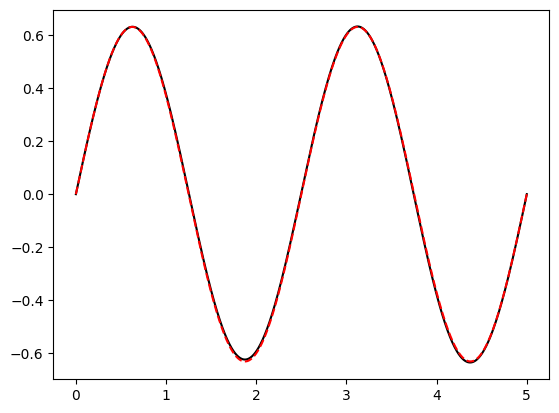

In [ ]:
import matplotlib.pyplot as plt
L=5
plt.plot(np.linspace(start=0, stop=L, num=n_variables[2]), egparesultWellexc3.data[-1, 0, :-1], 'k-')
plt.plot(np.linspace(start=0, stop=L, num=n_variables[2]), APsisWell['APsi3'], 'r--')